# GBT cross-check, regularised batch — LightGBM on the GNN inputs, no message passing (HI-Small)

- **Why a second batch:** the first batch (`GBT_fixed_features.ipynb`, `Outputs/GBT/`) memorises the train rows (train PR-AUC 1.00 against 0.55 on validation; validation loss rises from round 200 on while validation F1 and PR-AUC keep creeping up, so any ranking metric keeps the last round). This batch limits capacity and stops on the loss.
- **Same inputs, split and protocol:** the 93 columns the GNNs see (81 edge features + the 6 + 6 entity one-hots), train rows for fitting, validation for every choice, test scored once per seed, every metric on every split.
- **What changes (`GBT_VARIANT = reg`):** search space leaves 7–63, `min_data_in_leaf` 200–2,000, L2 1–100, learning rate 0.01–0.05, feature fraction 0.3–0.8; up to 2,000 rounds with **early stopping on the weighted validation loss** (patience 100 rounds) — every fit keeps its lowest-validation-loss round; the threshold is swept on validation at that round; search trials are ranked by **validation PR-AUC** (threshold-free). Same halving budget (x0 = 100, η = 2, r0 = 0.1), same four seeds.
- **Everything shared** comes from `gnn_core.py` through `gbt_core.py`; this notebook only sets the variant, the budget and the paths. Runs locally on CPU; search trials and finished runs are skipped on rerun.

## 0. Environment (local)

- Conda env `graph_feature_preprocessor` (torch + PyG to read the graph files, LightGBM 4.6.0 for the trees).
- The repo root is the working directory, so the committed `gnn_core.py` / `gbt_core.py` are imported.

In [1]:
import os
import sys
import json

import lightgbm
import numpy as np
import pandas as pd

sys.path.insert(0, os.getcwd())
import gnn_core as core
import gbt_core

print(f'lightgbm {lightgbm.__version__} | torch {core.torch.__version__} | threads {gbt_core.THREADS}')

lightgbm 4.6.0 | torch 2.8.0+cpu | threads 16


C:\Users\User\.conda\envs\graph_feature_preprocessor\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuration

- The only settings cell: the variant, the halving budget, the seeds and the paths.
- `OUT_ROOT` mirrors `Outputs/GBT_REG/` in the repo (the first batch stays in `Outputs/GBT/`); the search log lives in `OUT_ROOT/search/`.

In [2]:
VARIANT      = 'reg'                                        # GBT_VARIANT knob: v1 (first batch) | reg (this batch)
X0, ETA, R0  = gbt_core.X0, gbt_core.ETA, gbt_core.R0      # 100 configs -> 100 @ 10% -> 50 @ 20% -> 25 @ 40% -> 12 @ 80% -> 6 @ 100% of the train rows
SEEDS        = gbt_core.SEEDS                               # (42, 43, 44, 45); 42 is the run compared with the GNN runs
CHECK_EVERY  = gbt_core.CHECK_EVERY                         # history checkpoint every 25 boosting rounds

DATA_DIR = 'Data'
OUT_ROOT = 'Outputs/GBT_REG'
os.makedirs(f'{OUT_ROOT}/search', exist_ok=True)
settings = gbt_core.VARIANTS[VARIANT]
print(f"variant {VARIANT}: early stopping patience {settings['early_stopping']} on the weighted validation loss, "
      f"trials ranked by {settings['select']} | schedule {gbt_core.halving_schedule(X0, ETA, R0)} | seeds {SEEDS} | out {OUT_ROOT}")
print('search space:', json.dumps(settings['search_space']))

variant reg: early stopping patience 100 on the weighted validation loss, trials ranked by val_pr_auc | schedule [(100, 0.1), (50, 0.2), (25, 0.4), (12, 0.8), (6, 1.0)] | seeds (42, 43, 44, 45) | out Outputs/GBT_REG
search space: {"num_round": [2000, 2000, "int"], "num_leaves": [7, 63, "int"], "learning_rate": [0.01, 0.05, "log"], "min_data_in_leaf": [200, 2000, "int"], "feature_fraction": [0.3, 0.8, "float"], "bagging_fraction": [0.5, 1.0, "float"], "lambda_l1": [0.01, 10.0, "log"], "lambda_l2": [1.0, 100.0, "log"], "scale_pos_weight": [1.0, 10.0, "float"]}


## 2. Load data

- One row per edge from the graph files: `edge_attr` (81) ‖ `x[src]` (6) ‖ `x[dst]` (6); labels of the train / val windows from their own snapshots.
- The split boundaries and the laundering counts per split must match `Progress_Report.md` §4 (asserted).

In [3]:
data = gbt_core.load_gbt_data(DATA_DIR)
print(data['cols'][:3], '...', data['cols'][-3:])

GBT matrix (5077237, 93) float32 (1.76 GB): 81 edge + 6 src + 6 dst columns
train rows         0 – 3,046,341  n=3,046,342  laundering=2,297 (0.0754%)
val   rows 3,046,342 – 4,061,788  n=1,015,447  laundering=1,082 (0.1066%)
test  rows 4,061,789 – 5,077,236  n=1,015,448  laundering=1,143 (0.1126%)
['Amount_Log', 'Struct_Band', 'Hour_Sin'] ... ['dst_EntityType_Individual', 'dst_EntityType_Partnership', 'dst_EntityType_Sole']


## 3. Hyperparameter search — successive halving on the train rows, early stopping on validation loss

- Each round fits every surviving config on the most recent fraction of the train rows; the fit stops when the weighted validation loss has not improved for 100 rounds and keeps its best round; the config is scored on the full validation set at that round (PR-AUC ranks, F1 and threshold recorded); the best half survives.
- `search/trials.csv` gets one line per (trial, round) as soon as it finishes (with the kept `rounds`); `search/best_params.json` holds the winner of the last round (full train rows).
- Test is not touched here.

In [4]:
best_params, trials = gbt_core.successive_halving(data, f'{OUT_ROOT}/search', X0, ETA, R0, variant=VARIANT)
last_round = trials['round'].max()
trials[trials['round'] == last_round].sort_values('val_pr_auc', ascending=False).head(10)

successive halving (reg): x0=100 eta=2 r0=0.1 -> rounds [(100, 0.1), (50, 0.2), (25, 0.4), (12, 0.8), (6, 1.0)] | ranked by val_pr_auc | early stopping on weighted val loss, patience 100 | 0 trial rows already logged
--- round 1: 100 configs on the last 304,634 train rows (10%, 318 laundering) | 100 to fit


trial   0 | val F1 0.5314 @ 0.614 | PR-AUC 0.4919 | 14s | leaves 12 rounds 640 lr 0.020


trial   1 | val F1 0.5196 @ 0.525 | PR-AUC 0.4774 | 15s | leaves 47 rounds 566 lr 0.012


trial   2 | val F1 0.5228 @ 0.518 | PR-AUC 0.4736 | 14s | leaves 38 rounds 550 lr 0.014


trial   3 | val F1 0.5398 @ 0.247 | PR-AUC 0.4968 | 6s | leaves 46 rounds 124 lr 0.048


...

trial  36 | val F1 0.5708 @ 0.293 | PR-AUC 0.5230 | 117s | leaves 22 rounds 1067 lr 0.015


trial  66 | val F1 0.5893 @ 0.400 | PR-AUC 0.5412 | 193s | leaves 21 rounds 1369 lr 0.016


trial  58 | val F1 0.5839 @ 0.287 | PR-AUC 0.5347 | 53s | leaves 46 rounds 343 lr 0.038


trial   3 | val F1 0.5863 @ 0.332 | PR-AUC 0.5406 | 43s | leaves 46 rounds 190 lr 0.048
round 5 best: trial 84 val_pr_auc 0.5483 | median 0.5388 | 11.3 min
best configuration: trial 84 (val_pr_auc 0.5483 on the full train rows, 1380 rounds)
{
 "num_round": 2000,
 "num_leaves": 25,
 "learning_rate": 0.010407600769327152,
 "min_data_in_leaf": 545,
 "feature_fraction": 0.7637302292520134,
 "bagging_fraction": 0.7241036641284357,
 "lambda_l1": 0.08367682964780478,
 "lambda_l2": 15.738175470908685,
 "scale_pos_weight": 1.0658301066371407
}


,trial,round,fraction,n_rows,val_f1,threshold,val_pr_auc,rounds,seconds,params
188,84,5,1.0,3046342,0.589499,0.262370,0.548296,1380,192.440213,"{""num_round"": 2000, ""num_leaves"": 25, ""learnin..."
190,66,5,1.0,3046342,0.589275,0.400151,0.541178,1369,192.603395,"{""num_round"": 2000, ""num_leaves"": 21, ""learnin..."
192,3,5,1.0,3046342,0.586288,0.332069,0.540562,190,43.402000,"{""num_round"": 2000, ""num_leaves"": 46, ""learnin..."
187,19,5,1.0,3046342,0.581921,0.271753,0.536991,642,78.330542,"{""num_round"": 2000, ""num_leaves"": 32, ""learnin..."
191,58,5,1.0,3046342,0.583858,0.286846,0.534665,343,52.880981,"{""num_round"": 2000, ""num_leaves"": 46, ""learnin..."
189,36,5,1.0,3046342,0.570784,0.293419,0.523018,1067,116.921169,"{""num_round"": 2000, ""num_leaves"": 22, ""learnin..."


## 4. Final runs — four seeds with the chosen configuration

- One call per seed: full train rows → early stopping on the weighted validation loss → the lowest-loss round kept, threshold swept there → all splits scored → `results.json`, `history.csv`, `curves.png`, `best.txt`, `predictions.csv` under `OUT_ROOT/<run>/` (run names end in `_gbt-reg`).
- `history.csv` has one row per 25-round checkpoint plus the kept round; `curves.png` marks the kept round.

=== lightgbm_readout-full_seed-42_gbt-reg ===
features: 93 | seed 42 | rounds 2000 (cap; early stopping on weighted val loss, patience 100) | checkpoint every 25


round   25 | loss 0.0317 / 0.0426 | F1 0.3762 / 0.4817 @ 0.009 | PR-AUC 0.3049 / 0.3849 | 7s   (train / val)


round   50 | loss 0.0274 / 0.0362 | F1 0.4021 / 0.4900 @ 0.018 | PR-AUC 0.3439 / 0.4295 | 4s   (train / val)


round   75 | loss 0.0250 / 0.0329 | F1 0.4273 / 0.5060 @ 0.031 | PR-AUC 0.3636 / 0.4471 | 5s   (train / val)


round  100 | loss 0.0235 / 0.0308 | F1 0.4433 / 0.5128 @ 0.046 | PR-AUC 0.3779 / 0.4564 | 5s   (train / val)


...

round 1450 | loss 0.0152 / 0.0226 | F1 0.5692 / 0.5912 @ 0.207 | PR-AUC 0.5471 / 0.5489 | 75s   (train / val)


round 1475 | loss 0.0151 / 0.0226 | F1 0.5673 / 0.5918 @ 0.271 | PR-AUC 0.5488 / 0.5493 | 71s   (train / val)


early stopping: lowest weighted validation loss 0.0226 at round 1380 (validation F1 0.5895, threshold 0.262)


                    train     val    test
f1                 0.5628  0.5895  0.5253
precision          0.8348  0.8316  0.6940
recall             0.4245  0.4566  0.4226
pr_auc             0.5423  0.5483  0.4823
roc_auc            0.9927  0.9836  0.9817
precision_at_5pct  0.0146  0.0186  0.0195
recall_at_5pct     0.9673  0.8725  0.8670


predictions: 5,077,237 rows -> Outputs/GBT_REG/lightgbm_readout-full_seed-42_gbt-reg/predictions.csv


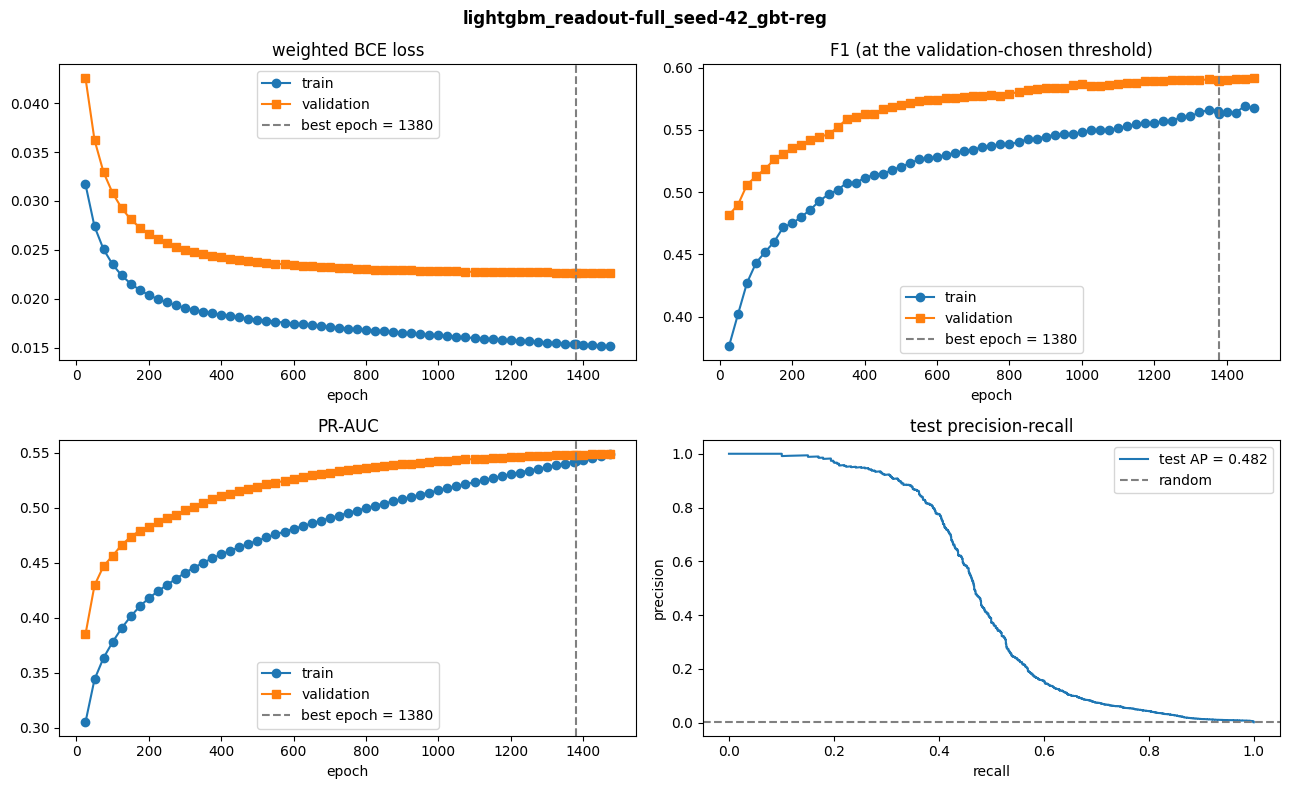

=== lightgbm_readout-full_seed-43_gbt-reg ===
features: 93 | seed 43 | rounds 2000 (cap; early stopping on weighted val loss, patience 100) | checkpoint every 25


round   25 | loss 0.0316 / 0.0426 | F1 0.3727 / 0.4854 @ 0.009 | PR-AUC 0.3103 / 0.3966 | 11s   (train / val)


round   50 | loss 0.0274 / 0.0362 | F1 0.3985 / 0.4926 @ 0.017 | PR-AUC 0.3452 / 0.4269 | 7s   (train / val)


round   75 | loss 0.0250 / 0.0329 | F1 0.4276 / 0.5079 @ 0.029 | PR-AUC 0.3629 / 0.4433 | 7s   (train / val)


round  100 | loss 0.0235 / 0.0308 | F1 0.4428 / 0.5149 @ 0.047 | PR-AUC 0.3778 / 0.4540 | 8s   (train / val)


...

round 1525 | loss 0.0150 / 0.0227 | F1 0.5718 / 0.5892 @ 0.241 | PR-AUC 0.5518 / 0.5496 | 64s   (train / val)


round 1550 | loss 0.0150 / 0.0227 | F1 0.5724 / 0.5903 @ 0.231 | PR-AUC 0.5535 / 0.5498 | 250s   (train / val)


early stopping: lowest weighted validation loss 0.0226 at round 1453 (validation F1 0.5895, threshold 0.234)


                    train     val    test
f1                 0.5678  0.5895  0.5249
precision          0.8175  0.8025  0.6745
recall             0.4349  0.4658  0.4296
pr_auc             0.5469  0.5489  0.4850
roc_auc            0.9931  0.9836  0.9817
precision_at_5pct  0.0147  0.0186  0.0196
recall_at_5pct     0.9717  0.8715  0.8705


predictions: 5,077,237 rows -> Outputs/GBT_REG/lightgbm_readout-full_seed-43_gbt-reg/predictions.csv


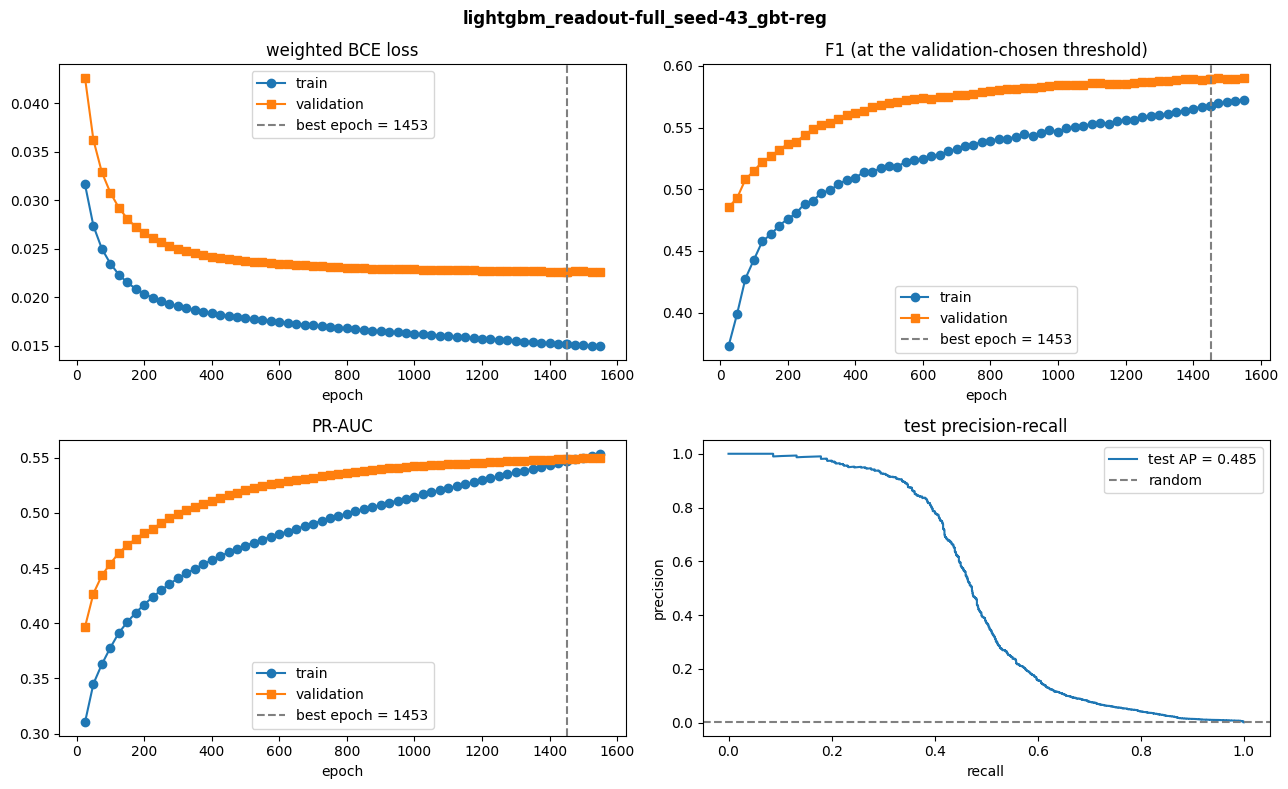

=== lightgbm_readout-full_seed-44_gbt-reg ===
features: 93 | seed 44 | rounds 2000 (cap; early stopping on weighted val loss, patience 100) | checkpoint every 25


round   25 | loss 0.0313 / 0.0419 | F1 0.4011 / 0.4817 @ 0.021 | PR-AUC 0.3081 / 0.3917 | 40s   (train / val)


round   50 | loss 0.0271 / 0.0356 | F1 0.3987 / 0.4877 @ 0.027 | PR-AUC 0.3411 / 0.4280 | 23s   (train / val)


round   75 | loss 0.0248 / 0.0324 | F1 0.4283 / 0.4997 @ 0.037 | PR-AUC 0.3633 / 0.4477 | 27s   (train / val)


round  100 | loss 0.0234 / 0.0304 | F1 0.4417 / 0.5073 @ 0.053 | PR-AUC 0.3781 / 0.4575 | 32s   (train / val)


...

round 1600 | loss 0.0148 / 0.0226 | F1 0.5734 / 0.5887 @ 0.257 | PR-AUC 0.5574 / 0.5495 | 64s   (train / val)


round 1625 | loss 0.0148 / 0.0226 | F1 0.5745 / 0.5894 @ 0.258 | PR-AUC 0.5592 / 0.5497 | 65s   (train / val)


early stopping: lowest weighted validation loss 0.0225 at round 1545 (validation F1 0.5878, threshold 0.229)


                    train     val    test
f1                 0.5724  0.5878  0.5209
precision          0.8168  0.7885  0.6476
recall             0.4406  0.4686  0.4357
pr_auc             0.5537  0.5492  0.4837
roc_auc            0.9933  0.9837  0.9819
precision_at_5pct  0.0147  0.0185  0.0196
recall_at_5pct     0.9730  0.8697  0.8696


predictions: 5,077,237 rows -> Outputs/GBT_REG/lightgbm_readout-full_seed-44_gbt-reg/predictions.csv


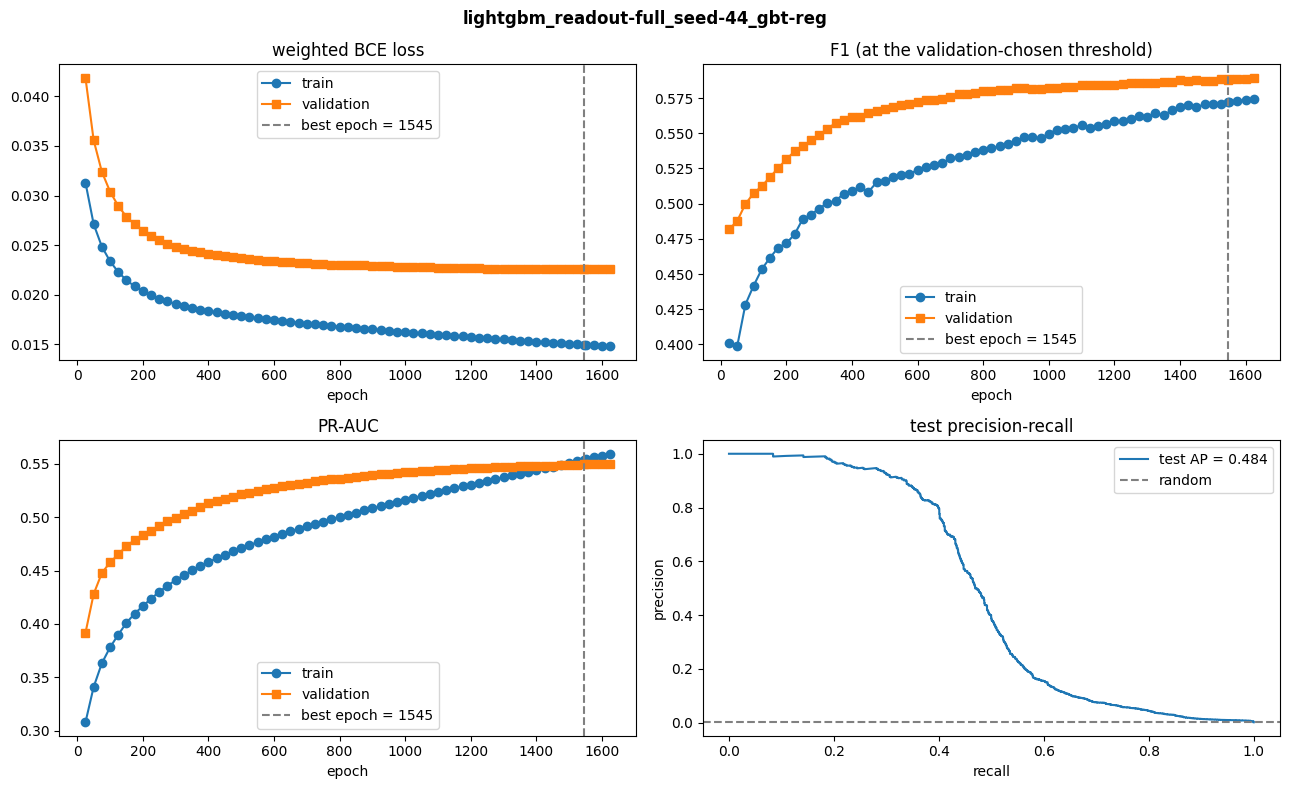

=== lightgbm_readout-full_seed-45_gbt-reg ===
features: 93 | seed 45 | rounds 2000 (cap; early stopping on weighted val loss, patience 100) | checkpoint every 25


round   25 | loss 0.0316 / 0.0423 | F1 0.3947 / 0.4812 @ 0.018 | PR-AUC 0.3099 / 0.3996 | 6s   (train / val)


round   50 | loss 0.0273 / 0.0359 | F1 0.4017 / 0.4978 @ 0.019 | PR-AUC 0.3433 / 0.4312 | 4s   (train / val)


round   75 | loss 0.0250 / 0.0327 | F1 0.4261 / 0.5056 @ 0.033 | PR-AUC 0.3626 / 0.4479 | 4s   (train / val)


round  100 | loss 0.0234 / 0.0305 | F1 0.4431 / 0.5128 @ 0.051 | PR-AUC 0.3780 / 0.4593 | 5s   (train / val)


...

round 1425 | loss 0.0152 / 0.0227 | F1 0.5673 / 0.5868 @ 0.193 | PR-AUC 0.5442 / 0.5473 | 56s   (train / val)


round 1450 | loss 0.0152 / 0.0227 | F1 0.5675 / 0.5873 @ 0.195 | PR-AUC 0.5459 / 0.5476 | 58s   (train / val)


early stopping: lowest weighted validation loss 0.0227 at round 1358 (validation F1 0.5862, threshold 0.189)


                    train     val    test
f1                 0.5650  0.5862  0.5093
precision          0.7635  0.7360  0.5962
recall             0.4484  0.4871  0.4444
pr_auc             0.5394  0.5464  0.4822
roc_auc            0.9927  0.9836  0.9817
precision_at_5pct  0.0146  0.0185  0.0195
recall_at_5pct     0.9700  0.8688  0.8670


predictions: 5,077,237 rows -> Outputs/GBT_REG/lightgbm_readout-full_seed-45_gbt-reg/predictions.csv


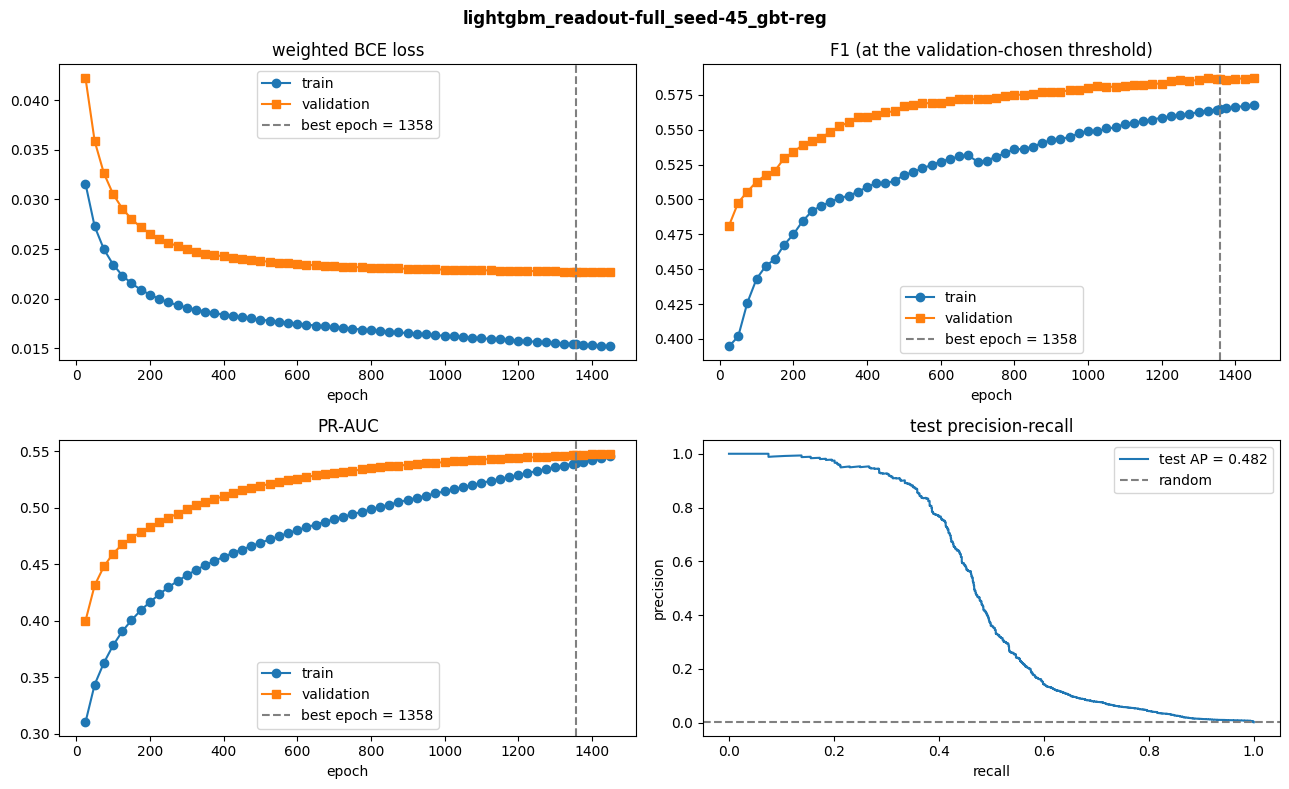

batch complete


In [5]:
rows = []
for seed in SEEDS:
    print('=' * 90)
    rows.append(gbt_core.train_final(best_params, data, seed, OUT_ROOT, CHECK_EVERY, variant=VARIANT))
print('=' * 90)
print('batch complete')

## 5. Comparison across the seeds

- `batch_summary_gbt_reg.csv` holds every `<split>_<metric>` column plus `threshold`, `best_epoch` (kept round), `params` (trees kept), `invariant_params` (0 by convention), `gbt_variant`.
- `seed_summary_gbt_reg.csv`: mean ± std over the four seeds. Only test F1 is a fair score here — validation picked the hyperparameters, the kept round and the threshold.

In [6]:
summary = core.summarize_batch(rows, OUT_ROOT, 'batch_summary_gbt_reg.csv')
display(summary[['gbt_variant'] + core.DISPLAY_COLS].round(4))
seeds = gbt_core.seed_summary(rows, OUT_ROOT, 'seed_summary_gbt_reg.csv')
seeds[['n_seeds', 'val_f1_mean', 'val_f1_std', 'test_f1_mean', 'test_f1_std',
       'test_pr_auc_mean', 'test_pr_auc_std', 'best_epoch_mean']].round(4)

4 runs -> Outputs/GBT_REG/batch_summary_gbt_reg.csv | invariant_params = 0 in the first row (identical in every row)


,gbt_variant,run,best_epoch,threshold,val_f1,test_f1,test_precision,test_recall,test_pr_auc,test_precision_at_5pct,test_recall_at_5pct,params,invariant_params
0,reg,lightgbm_readout-full_seed-42_gbt-reg,1380,0.2624,0.5895,0.5253,0.6940,0.4226,0.4823,0.0195,0.8670,1380,0
1,reg,lightgbm_readout-full_seed-43_gbt-reg,1453,0.2336,0.5895,0.5249,0.6745,0.4296,0.4850,0.0196,0.8705,1453,0
2,reg,lightgbm_readout-full_seed-44_gbt-reg,1545,0.2291,0.5878,0.5209,0.6476,0.4357,0.4837,0.0196,0.8696,1545,0
3,reg,lightgbm_readout-full_seed-45_gbt-reg,1358,0.1886,0.5862,0.5093,0.5962,0.4444,0.4822,0.0195,0.8670,1358,0


4 seeds -> Outputs/GBT_REG/seed_summary_gbt_reg.csv


,n_seeds,val_f1_mean,val_f1_std,test_f1_mean,test_f1_std,test_pr_auc_mean,test_pr_auc_std,best_epoch_mean
0,4,0.5883,0.0016,0.5201,0.0075,0.4833,0.0013,1434.0
